# Cardiotocography (CTG) Classification — Gaussian Naive Bayes
This notebook loads the CTG dataset, prepares the features/target, trains a Gaussian Naive Bayes classifier, and evaluates it.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

%matplotlib inline

## 1. Load the dataset

In [2]:
df = pd.read_excel(
    "data/CTG.xls",
    sheet_name="Raw Data"
)

df.head()

,FileName,Date,SegFile,b,e,LBE,LB,AC,FM,UC,...,C,D,E,AD,DE,LD,FS,SUSP,CLASS,NSP
0,NaN,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Variab10.txt,1996-12-01,CTG0001.txt,240.0,357.0,120.0,120.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,9.0,2.0
2,Fmcs_1.txt,1996-05-03,CTG0002.txt,5.0,632.0,132.0,132.0,4.0,0.0,4.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,6.0,1.0
3,Fmcs_1.txt,1996-05-03,CTG0003.txt,177.0,779.0,133.0,133.0,2.0,0.0,5.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,6.0,1.0
4,Fmcs_1.txt,1996-05-03,CTG0004.txt,411.0,1192.0,134.0,134.0,2.0,0.0,6.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,6.0,1.0


## 2. Clean the data and select features/target

The raw sheet has blank separator rows at the start/end and several non-predictive identifier columns (`FileName`, `Date`, `SegFile`, `b`, `e`). The target used here is `NSP` (1 = Normal, 2 = Suspect, 3 = Pathologic).

In [3]:
# Drop the blank separator rows (rows with no target value)
df = df.dropna(subset=["NSP"])

# Feature columns: the CTG morphological/measurement features
feature_cols = [
    "LB", "AC", "FM", "UC", "DL", "DS", "DP", "DR",
    "ASTV", "MSTV", "ALTV", "MLTV",
    "Width", "Min", "Max", "Nmax", "Nzeros",
    "Mode", "Mean", "Median", "Variance", "Tendency"
]

X = df[feature_cols]
y = df["NSP"].astype(int)

print(f"Feature matrix shape: {X.shape}")
print("Class distribution (1=Normal, 2=Suspect, 3=Pathologic):")
print(y.value_counts().sort_index())

Feature matrix shape: (2126, 22)
Class distribution (1=Normal, 2=Suspect, 3=Pathologic):
NSP
1    1655
2     295
3     176
Name: count, dtype: int64


## 3. Train/test split and feature scaling

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print(f"Train size: {X_train.shape[0]}, Test size: {X_test.shape[0]}")

Train size: 1700, Test size: 426


## 4. Gaussian Naive Bayes model

In [5]:
from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB()

nb_model.fit(
    X_train,
    y_train
)

y_train_pred_nb = nb_model.predict(X_train)
y_test_pred_nb = nb_model.predict(X_test)

## 5. Evaluation metrics

In [6]:
accuracy_nb = accuracy_score(
    y_test,
    y_test_pred_nb
)

precision_nb = precision_score(
    y_test,
    y_test_pred_nb,
    average="macro"
)

recall_nb = recall_score(
    y_test,
    y_test_pred_nb,
    average="macro"
)

f1_nb = f1_score(
    y_test,
    y_test_pred_nb,
    average="macro"
)

print("Gaussian Naive Bayes Results")
print("----------------------------")
print(f"Accuracy : {accuracy_nb:.4f}")
print(f"Precision: {precision_nb:.4f}")
print(f"Recall   : {recall_nb:.4f}")
print(f"F1-score : {f1_nb:.4f}")
print(
    classification_report(
        y_test,
        y_test_pred_nb,
        target_names=[
            "Normal",
            "Suspect",
            "Pathologic"
        ]
    )
)

Gaussian Naive Bayes Results
----------------------------
Accuracy : 0.8263
Precision: 0.7159
Recall   : 0.7127
F1-score : 0.6865
              precision    recall  f1-score   support

      Normal       0.96      0.87      0.91       332
     Suspect       0.46      0.81      0.59        59
  Pathologic       0.73      0.46      0.56        35

    accuracy                           0.83       426
   macro avg       0.72      0.71      0.69       426
weighted avg       0.87      0.83      0.84       426



## 6. Confusion matrix

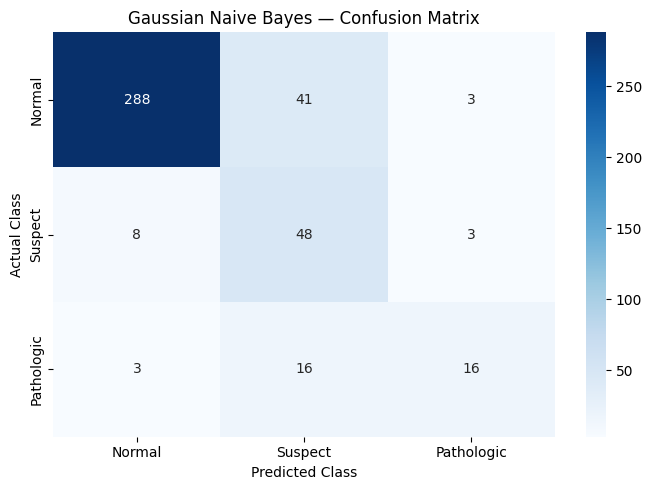

In [7]:
cm_nb = confusion_matrix(
    y_test,
    y_test_pred_nb
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_nb,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Normal",
        "Suspect",
        "Pathologic"
    ],
    yticklabels=[
        "Normal",
        "Suspect",
        "Pathologic"
    ]
)

plt.title("Gaussian Naive Bayes — Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()